# Predict TADF photoluminescence from a SMILES string

This notebook runs the published heterogeneous GraphSAGE model on one molecule and prints the predicted photoluminescence energy (eV) and wavelength (nm).

Paper: [Machine-Learning Predictions of Photoluminescence in Molecules Exhibiting Thermally Activated Delayed Fluorescence with Implicit Experimental Validation](https://doi.org/10.1021/acs.jcim.6c00425).

Use a **CPU** runtime. A GPU is unnecessary for a single molecule.

During cloning the repository and installing required packages, expect a few more minutes, mostly spent installing dependencies. The first prediction also builds the training-set graphs so the model can undo output normalization.


In [10]:
import os
import sys

BRANCH = "feat/add-colab-for-new-user"
REPO_URL = "https://github.com/Dingyun-Huang/tadf-photoluminescence-ml-prediction.git"
REPO_DIR = "/content/tadf-photoluminescence-ml-prediction"

if not os.path.isdir(REPO_DIR):
    !git clone --depth 1 --branch {BRANCH} {REPO_URL} {REPO_DIR}

%cd {REPO_DIR}


/content/tadf-photoluminescence-ml-prediction


In [12]:
import os

os.chdir(REPO_DIR)

%pip install -q --upgrade pip
%pip install -q -r requirements-model-training.txt

try:
    import rdkit
    import torch
    import torch_geometric
except ImportError as exc:
    raise SystemExit(
        "Imports failed after install. In Colab, open Runtime → Restart session, "
        "then run every cell again from the top.\n"
        f"Original error: {exc}"
    ) from exc

print("torch", torch.__version__)
print("pyg", torch_geometric.__version__)
print("rdkit", rdkit.__version__)


torch 2.4.1+cpu
pyg 2.6.1
rdkit 2025.09.1


## Example prediction

This is the same command as in the README. It must run from `src/gnn` so the config and checkpoint paths resolve. The first run processes the TadfPL training split and can take a minute.


In [ ]:
%cd {REPO_DIR}/src/gnn
!python run_inference.py --smiles "c1ccc2c(c1)Oc1ccccc1N2c1ccc2c3c(cccc13)-c1nc3cc(-c4ccncc4)c(-c4ccncc4)cc3nc1-2"


## Try your own SMILES

Edit the SMILES below (or use the form field in Colab) and run the cell. The drawing is the input structure; the numbers are the model prediction.


Using heterogeneous GNN architecture


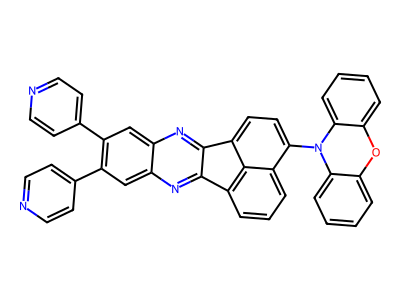

SMILES: c1ccc2c(c1)Oc1ccccc1N2c1ccc2c3c(cccc13)-c1nc3cc(-c4ccncc4)c(-c4ccncc4)cc3nc1-2
Predicted PL energy: 2.5151 eV
Predicted PL wavelength: 493.0 nm


In [13]:
import os

from IPython.display import display
from rdkit import Chem
from rdkit.Chem import Draw

os.chdir(os.path.join(REPO_DIR, "src", "gnn"))
from run_inference import predict_pl

smiles = "c1ccc2c(c1)Oc1ccccc1N2c1ccc2c3c(cccc13)-c1nc3cc(-c4ccncc4)c(-c4ccncc4)cc3nc1-2"  # @param {type:"string"}

result = predict_pl(smiles)
mol = Chem.MolFromSmiles(smiles)
if mol is not None:
    display(Draw.MolToImage(mol, size=(400, 300)))

print(f"SMILES: {result['smiles']}")
print(f"Predicted PL energy: {result['pl_ev']:.4f} eV")
print(f"Predicted PL wavelength: {result['pl_nm']:.1f} nm")


## If a cell fails

- **The first cell stops on the Python version.** The connected runtime is 3.12 or newer. Open **Runtime → Change runtime type**, set **Runtime version** to **2025.07** (Python 3.11), reconnect, and run every cell again from the top.
- **Imports fail right after `pip install`.** Colab sometimes keeps the previous PyTorch in memory. Use **Runtime → Restart session**, then run every cell again from the top.
- **`Model archive not found`.** The clone did not include `model_archive/model_8_layer_28_h.pt`. Re-run the clone cell and confirm `BRANCH` is `feat/add-colab-for-new-user`.
- **`Invalid SMILES string`.** RDKit could not parse the string. Check brackets and aromatic atoms, then run the prediction cell again.

Training is not run here. On a local checkout, from `src/gnn`:

```bash
python run_experiment.py --seed 2000
```

See the repository README for configuration, citation, and the full install notes.
